# Repeater-Chain Surrogate Evaluation

Compare the Transformer-MDN surrogate with held-out SeQUeNCe simulations, in two passes:

1. **One condition in depth** - paired `(time, fidelity)` samples for the condition selected by
   `TEST_FILE_INDEX`, with marginal, joint, and 2D density visualizations.
2. **Every condition in the testing set** - the same metrics scored across all held-out
   conditions, aggregated into a table and broken down by chain length and chain distance.

Scored metrics:

- time and fidelity Wasserstein distances;
- time and fidelity two-sample KS statistics;
- standardized joint energy distance for the paired distribution;
- time-fidelity correlation;
- sample-generation runtime.

Lower is better for Wasserstein, KS, and energy distance. The correlation difference should be close to zero.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from chain_metrics import SWEEP_METRICS, read_condition, score_condition, score_conditions
from train_surrogate_chain import LINK_DISTANCES_NAME, build_condition_sampler, load_model, resolve_device

## Shared readers and metrics

Reading conditions and scoring them lives in `chain_metrics.py`, so this notebook, the
`tune_surrogate_chain.py` sweep, and anything else comparing surrogate against SeQUeNCe report the
same numbers:

- `read_condition(path)` returns the chain configuration and paired `(time, fidelity)` samples;
- `score_condition(sequence, surrogate)` returns every distribution-comparison metric for one condition;
- `score_conditions(paths, sampler)` scores a whole testing set with one already-built sampler;
- `SWEEP_METRICS` names the six metrics worth aggregating. Lower is better for all of them.

In [54]:
MODEL_PATH = None
MODEL_DIRECTORY = PROJECT_ROOT / "models"
TEST_DIRECTORY = PROJECT_ROOT / "chain/testing/h5"
# TEST_FILE_INDEX = 158
# TEST_FILE_INDEX = 121
TEST_FILE_INDEX = 52
SAMPLE_COUNT = 2000
SEED = 7
SWEEP_CSV_PATH = PROJECT_ROOT / "models/chain_condition_metrics.csv"

if MODEL_PATH is None:
    model_paths = sorted(MODEL_DIRECTORY.glob("*.pt"))
    if not model_paths:
        raise FileNotFoundError(f"No chain model files found under {MODEL_DIRECTORY}")
    MODEL_PATH = model_paths[-1]

test_paths = sorted(TEST_DIRECTORY.glob("*.h5"))
if not test_paths:
    raise FileNotFoundError(f"No HDF5 files found under {TEST_DIRECTORY}")
if not 0 <= TEST_FILE_INDEX < len(test_paths):
    raise IndexError(f"TEST_FILE_INDEX must be between 0 and {len(test_paths) - 1}")

test_path = test_paths[TEST_FILE_INDEX]
device = resolve_device("cuda" if torch.cuda.is_available() else "cpu")
artifact = load_model(MODEL_PATH, device)
sampler = build_condition_sampler(artifact, device)
sampler(read_condition(test_path)[0], 8, SEED)  # Warm up so the timings below exclude first-call overhead.
if device.type == "cuda":
    torch.cuda.synchronize(device)

print(f"Model: {MODEL_PATH}")
print(f"Test conditions: {len(test_paths)}")
print(f"Deep-dive test file: {test_path}")
print(f"Device: {device}")

Model: models/combo_big_lr_validation_nll=-0.8771663870.pt
Test conditions: 250
Deep-dive test file: chain/testing/h5/n=13_lds=15602-17881-5022-17562-16795-6976-2191-15666-16685-9752-4125-3768_sp=0.94_if=0.99_ct=0.94_cdh=0.031_me=0.81_de=0.99_a=0.00026_cdn=0.061.h5
Device: cpu


## Load one SeQUeNCe condition and generate surrogate samples

The HDF5 attributes provide the variable-length link-distance sequence and the eight homogeneous global features. Time and fidelity are loaded as paired samples.

In [55]:
config, sequence_samples = read_condition(test_path)
if device.type == "cuda":
    torch.cuda.synchronize(device)
sample_start = perf_counter()
surrogate_samples = sampler(config, SAMPLE_COUNT, SEED)
if device.type == "cuda":
    torch.cuda.synchronize(device)
sample_elapsed_seconds = perf_counter() - sample_start

print(f"Nodes: {len(config[LINK_DISTANCES_NAME]) + 1}")
print(f"Link distances: {config[LINK_DISTANCES_NAME]}")
print(f"SeQUeNCe samples: {len(sequence_samples):,}")
print(f"Surrogate samples: {len(surrogate_samples):,}")
print(f"End-to-end surrogate sampling time: {sample_elapsed_seconds:.6f} seconds")
print(f"Surrogate sampling rate: {len(surrogate_samples) / sample_elapsed_seconds:,.0f} samples/second")

Nodes: 13
Link distances: [15602.0, 17881.0, 5022.0, 17562.0, 16795.0, 6976.0, 2191.0, 15666.0, 16685.0, 9752.0, 4125.0, 3768.0]
SeQUeNCe samples: 2,000
Surrogate samples: 2,000
End-to-end surrogate sampling time: 0.017988 seconds
Surrogate sampling rate: 111,187 samples/second


## Distribution metrics

Marginal Wasserstein and KS metrics evaluate time and fidelity separately. Joint energy distance compares the complete paired distribution after standardizing both dimensions using the SeQUeNCe scale. This prevents milliseconds from numerically dominating fidelity.

In [56]:
metrics = score_condition(sequence_samples, surrogate_samples)
sequence_correlation = metrics["sequence_correlation"]
surrogate_correlation = metrics["surrogate_correlation"]

print(f"Time Wasserstein:                 {metrics['time_wasserstein_ms']:.6f} ms")
print(f"Normalized time Wasserstein:      {metrics['normalized_time_wasserstein']:.6f}")
print(f"Time KS statistic:                {metrics['time_ks']:.6f}")
print(f"Fidelity Wasserstein:             {metrics['fidelity_wasserstein']:.6f}")
print(f"Fidelity KS statistic:            {metrics['fidelity_ks']:.6f}")
print(f"Standardized joint energy:        {metrics['joint_energy']:.6f}")
print(f"SeQUeNCe time-fidelity corr.:     {sequence_correlation:.6f}")
print(f"Surrogate time-fidelity corr.:    {surrogate_correlation:.6f}")
print(f"Absolute correlation difference:  {metrics['absolute_correlation_difference']:.6f}")

Time Wasserstein:                 0.295980 ms
Normalized time Wasserstein:      0.015084
Time KS statistic:                0.022000
Fidelity Wasserstein:             0.002139
Fidelity KS statistic:            0.040500
Standardized joint energy:        0.025434
SeQUeNCe time-fidelity corr.:     -0.884525
Surrogate time-fidelity corr.:    -0.869602
Absolute correlation difference:  0.014923


## Summary statistics

Percentiles are reported from 10% through 90%, followed by 95% and 99%.

In [57]:
def summarize(samples):
    """Return mean, standard deviation, and selected percentiles."""
    percentiles = list(range(10, 100, 10)) + [95, 99]
    summary = {"mean": float(np.mean(samples)), "std": float(np.std(samples))}
    for percentile in percentiles:
        summary[f"{percentile}%"] = float(np.percentile(samples, percentile))
    return summary


def print_summary(name, sequence, surrogate):
    """Print aligned SeQUeNCe and surrogate summary statistics."""
    sequence_summary = summarize(sequence)
    surrogate_summary = summarize(surrogate)
    print(name)
    print(f"{'Metric':<10}{'SeQUeNCe':>16}{'Surrogate':>16}")
    for metric in sequence_summary:
        print(f"{metric:<10}{sequence_summary[metric]:>16.6f}{surrogate_summary[metric]:>16.6f}")
    print()


print_summary("Time [ms]", sequence_samples[:, 0], surrogate_samples[:, 0])
print_summary("Fidelity", sequence_samples[:, 1], surrogate_samples[:, 1])

Time [ms]
Metric            SeQUeNCe       Surrogate
mean             19.622700       19.596426
std               9.542652        9.137481
10%              10.744637       10.461820
20%              12.432645       12.259906
30%              13.890568       13.846526
40%              15.506638       15.631181
50%              17.292387       17.340477
60%              19.305305       19.293371
70%              21.907383       21.918400
80%              25.360540       25.619192
90%              31.189825       31.974194
95%              37.233459       37.257500
99%              55.866768       52.259453

Fidelity
Metric            SeQUeNCe       Surrogate
mean              0.775067        0.777200
std               0.039670        0.038672
10%               0.723013        0.724928
20%               0.744642        0.747218
30%               0.759968        0.761566
40%               0.770365        0.773886
50%               0.780766        0.784573
60%               0.791293        

## Marginal distributions

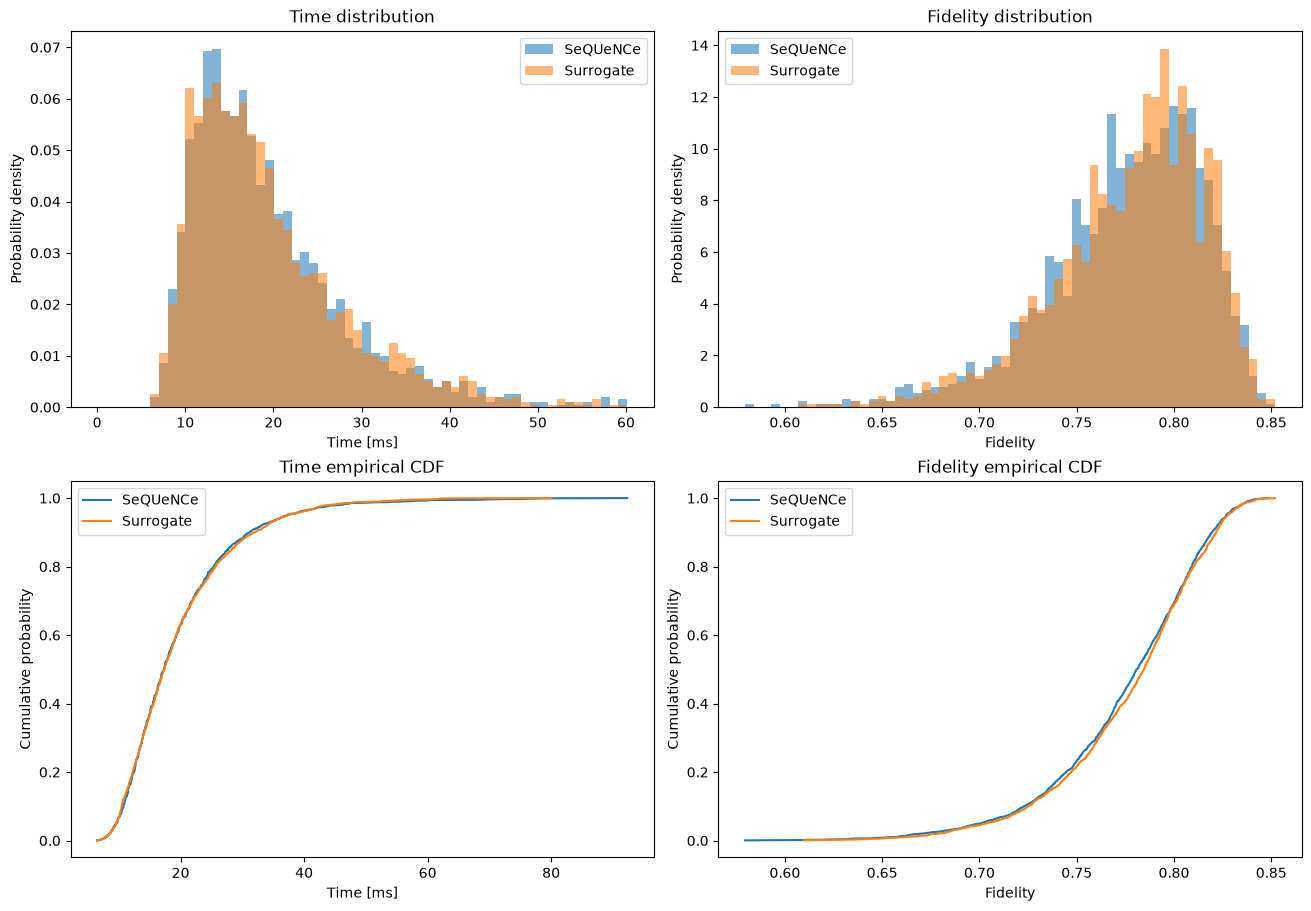

In [58]:
combined_time = np.concatenate((sequence_samples[:, 0], surrogate_samples[:, 0]))
combined_fidelity = np.concatenate((sequence_samples[:, 1], surrogate_samples[:, 1]))
time_histogram_limit = float(np.quantile(combined_time, 0.995))
fidelity_histogram_range = (float(np.min(combined_fidelity)), float(np.max(combined_fidelity)))


def ecdf(samples):
    """Return sorted values and empirical cumulative probabilities."""
    values = np.sort(samples)
    probabilities = np.arange(1, len(values) + 1) / len(values)
    return values, probabilities


def plot_marginal_distributions():
    """Plot time and fidelity histograms and empirical CDFs for both sample sources."""
    figure, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
    axes[0, 0].hist(sequence_samples[:, 0], bins=60, range=(0, time_histogram_limit), density=True, alpha=0.55, label="SeQUeNCe")
    axes[0, 0].hist(surrogate_samples[:, 0], bins=60, range=(0, time_histogram_limit), density=True, alpha=0.55, label="Surrogate")
    axes[0, 0].set(title="Time distribution", xlabel="Time [ms]", ylabel="Probability density")
    axes[0, 0].legend()

    axes[0, 1].hist(sequence_samples[:, 1], bins=60, range=fidelity_histogram_range, density=True, alpha=0.55, label="SeQUeNCe")
    axes[0, 1].hist(surrogate_samples[:, 1], bins=60, range=fidelity_histogram_range, density=True, alpha=0.55, label="Surrogate")
    axes[0, 1].set(title="Fidelity distribution", xlabel="Fidelity", ylabel="Probability density")
    axes[0, 1].legend()

    for samples, label in ((sequence_samples[:, 0], "SeQUeNCe"), (surrogate_samples[:, 0], "Surrogate")):
        values, probabilities = ecdf(samples)
        axes[1, 0].plot(values, probabilities, label=label)
    axes[1, 0].set(title="Time empirical CDF", xlabel="Time [ms]", ylabel="Cumulative probability")
    axes[1, 0].legend()

    for samples, label in ((sequence_samples[:, 1], "SeQUeNCe"), (surrogate_samples[:, 1], "Surrogate")):
        values, probabilities = ecdf(samples)
        axes[1, 1].plot(values, probabilities, label=label)
    axes[1, 1].set(title="Fidelity empirical CDF", xlabel="Fidelity", ylabel="Cumulative probability")
    axes[1, 1].legend()
    plt.show()


plot_marginal_distributions()

## Joint time-fidelity distribution

Both panels use the same axis limits. Similar orientation, clustering, and spread indicate that the full-covariance MDN has learned the dependence between time and fidelity.

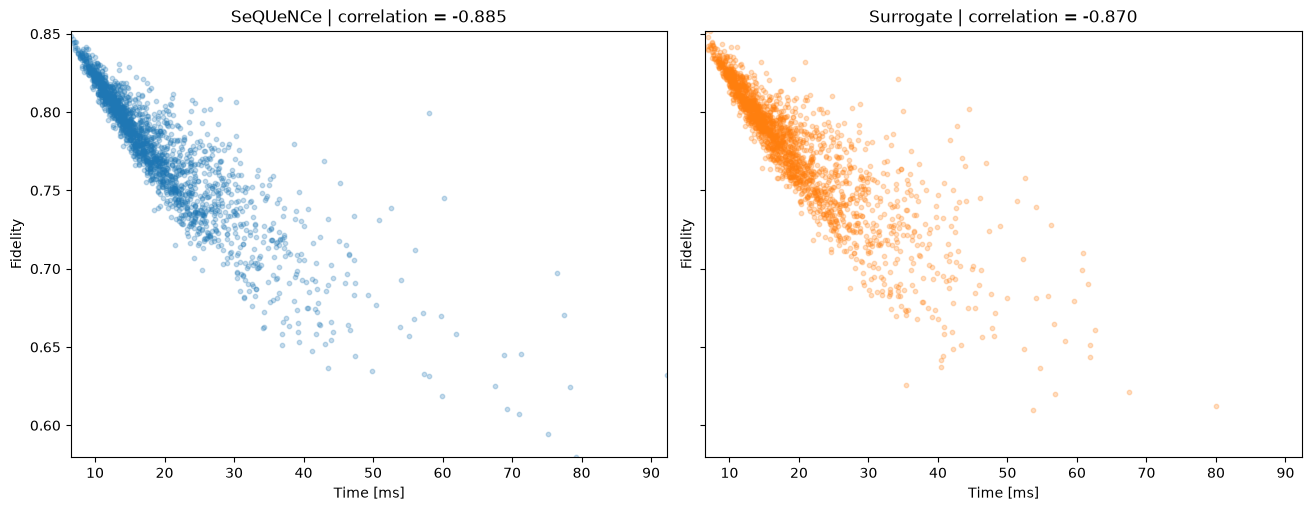

In [59]:
def plot_joint_distribution():
    """Plot paired time-fidelity scatters for both sample sources on shared axes."""
    plot_rng = np.random.default_rng(SEED)
    sequence_plot = sequence_samples[plot_rng.choice(len(sequence_samples), min(5000, len(sequence_samples)), replace=False)]
    surrogate_plot = surrogate_samples[plot_rng.choice(len(surrogate_samples), min(5000, len(surrogate_samples)), replace=False)]
    combined_plot = np.vstack((sequence_plot, surrogate_plot))
    time_limits = (float(np.min(combined_plot[:, 0])), float(np.max(combined_plot[:, 0])))
    fidelity_limits = (float(np.min(combined_plot[:, 1])), float(np.max(combined_plot[:, 1])))

    figure, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, constrained_layout=True)
    axes[0].scatter(sequence_plot[:, 0], sequence_plot[:, 1], s=10, alpha=0.25)
    axes[0].set_title(f"SeQUeNCe | correlation = {sequence_correlation:.3f}")
    axes[1].scatter(surrogate_plot[:, 0], surrogate_plot[:, 1], s=10, alpha=0.25, color="tab:orange")
    axes[1].set_title(f"Surrogate | correlation = {surrogate_correlation:.3f}")
    for axis in axes:
        axis.set(xlabel="Time [ms]", ylabel="Fidelity", xlim=time_limits, ylim=fidelity_limits)
    plt.show()


plot_joint_distribution()

## 2D time-fidelity density

The scatter plots show where samples land but saturate in the dense core. These panels bin the
same paired samples onto shared edges so the two densities are directly comparable, and the third
panel shows the signed difference. A near-empty difference panel means the surrogate reproduces
the joint structure, not just the two marginals. Time is clipped at the 99.5th percentile of the
combined samples so the heavy tail does not compress the bulk of the distribution into one column.


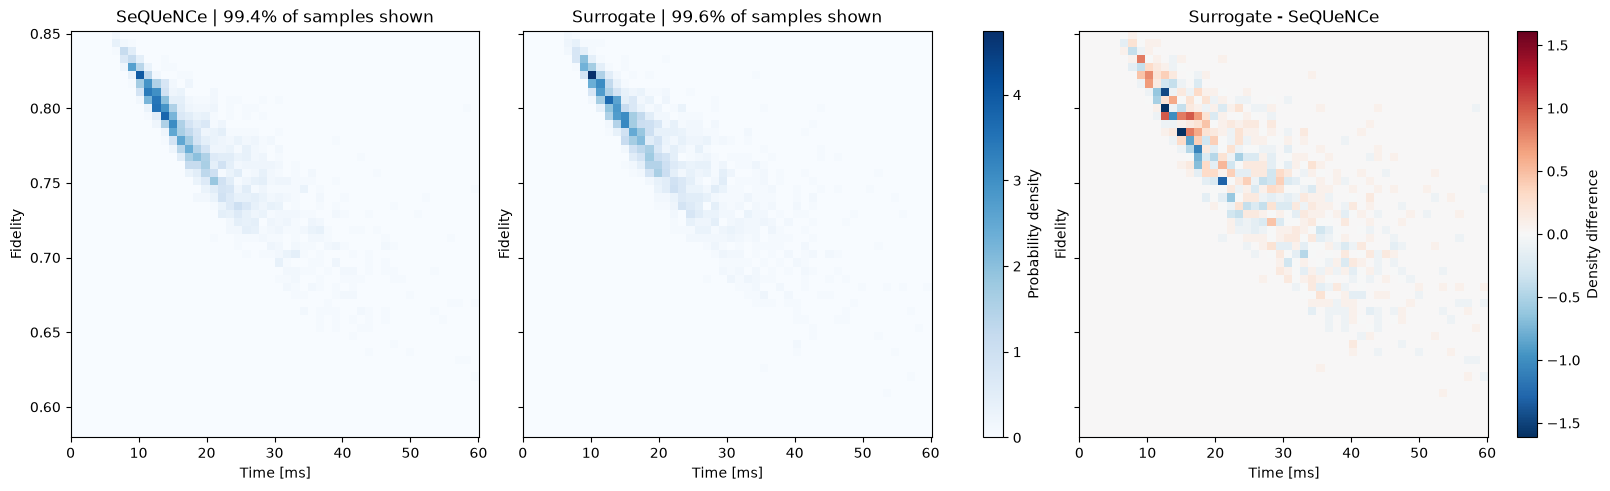

Maximum absolute density difference: 1.614886
Total absolute density difference:   0.489491


In [60]:
DENSITY_BINS = 50  # 2,000 samples per condition; finer grids turn the difference panel into noise

density_time_limit = float(np.quantile(combined_time, 0.995))
time_edges = np.linspace(0.0, density_time_limit, DENSITY_BINS + 1)
fidelity_edges = np.linspace(fidelity_histogram_range[0], fidelity_histogram_range[1], DENSITY_BINS + 1)


def joint_density(samples):
    """Return the 2D probability density of paired samples on the shared bin edges."""
    density, _, _ = np.histogram2d(samples[:, 0], samples[:, 1], bins=(time_edges, fidelity_edges), density=True)
    return density.T


def retained_fraction(samples):
    """Return the fraction of samples falling inside the plotted time range."""
    return float(np.mean(samples[:, 0] <= density_time_limit))


sequence_density = joint_density(sequence_samples)
surrogate_density = joint_density(surrogate_samples)
density_difference = surrogate_density - sequence_density
difference_limit = float(np.abs(density_difference).max())


def plot_joint_density():
    """Plot both binned joint densities on a shared color scale and their signed difference."""
    density_limit = float(max(sequence_density.max(), surrogate_density.max()))

    figure, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True, constrained_layout=True)
    for axis, density, name, samples in (
        (axes[0], sequence_density, "SeQUeNCe", sequence_samples),
        (axes[1], surrogate_density, "Surrogate", surrogate_samples),
    ):
        mesh = axis.pcolormesh(time_edges, fidelity_edges, density, cmap="Blues", vmin=0.0, vmax=density_limit)
        axis.set_title(f"{name} | {retained_fraction(samples):.1%} of samples shown")
    figure.colorbar(mesh, ax=axes[:2], label="Probability density")

    difference_mesh = axes[2].pcolormesh(
        time_edges, fidelity_edges, density_difference, cmap="RdBu_r", vmin=-difference_limit, vmax=difference_limit
    )
    axes[2].set_title("Surrogate - SeQUeNCe")
    figure.colorbar(difference_mesh, ax=axes[2], label="Density difference")

    for axis in axes:
        axis.set(xlabel="Time [ms]", ylabel="Fidelity")
    plt.show()


plot_joint_density()

print(f"Maximum absolute density difference: {difference_limit:.6f}")
print(f"Total absolute density difference:   {float(np.abs(density_difference).sum() * np.diff(time_edges)[0] * np.diff(fidelity_edges)[0]):.6f}")


# Sweep every held-out testing condition

One condition can be unrepresentative: the surrogate may fit a nine-link chain well and still miss
short chains or long-latency ones. This section scores **every** file in `TEST_DIRECTORY` with the
same `score_condition` used above, reusing a single loaded model so the sweep costs milliseconds
per condition.

Each row records the chain structure, the eight homogeneous global features, and every metric, so
the results can be sliced later to see *where* in configuration space the surrogate struggles.

In [61]:
sweep_start = perf_counter()
records = score_conditions(test_paths, sampler, SAMPLE_COUNT, SEED)
sweep_elapsed_seconds = perf_counter() - sweep_start

results = pd.DataFrame.from_records(records)
print(f"Scored {len(results)} conditions in {sweep_elapsed_seconds:.1f} seconds "
      f"({sweep_elapsed_seconds / len(results) * 1e3:.1f} ms per condition)")
print(f"Chain lengths: {results['nodes'].min()} to {results['nodes'].max()} nodes")
results.head()

Scored 250 conditions in 5.5 seconds (22.2 ms per condition)
Chain lengths: 3 to 17 nodes


,condition,test_index,nodes,total_distance_km,mean_link_distance_km,max_link_distance_km,memory_efficiency,detector_efficiency,attenuation,classical_delay_node,...,time_ks,time_ks_pvalue,fidelity_wasserstein,fidelity_ks,fidelity_ks_pvalue,joint_energy,logit_fidelity_std_ratio,sequence_correlation,surrogate_correlation,absolute_correlation_difference
0,n=10_lds=10234-11892-13614-12521-15554-17645-4...,0,10,120.620,13.402223,18.060,1.00,0.99,0.00027,0.072,...,0.0275,0.436093,0.000372,0.0220,0.718514,0.000000,0.966085,-0.779548,-0.732191,0.047357
1,n=10_lds=10725-15348-19059-1662-3739-16636-190...,1,10,98.854,10.983777,19.059,0.96,0.96,0.00025,0.093,...,0.0325,0.241482,0.001270,0.0345,0.184886,0.050991,1.101308,-0.668837,-0.751791,0.082953
2,n=10_lds=11313-1714-5935-10404-14342-10651-221...,2,10,76.049,8.449889,16.024,0.98,0.99,0.00023,0.086,...,0.0795,0.000006,0.001651,0.0655,0.000374,0.101848,0.986183,-0.928938,-0.922326,0.006611
3,n=10_lds=12979-13562-10232-12121-7516-15019-10...,3,10,91.764,10.196000,15.019,0.70,0.97,0.00024,0.078,...,0.0415,0.063831,0.002101,0.0575,0.002682,0.087090,0.953870,-0.738149,-0.751686,0.013537
4,n=10_lds=14963-15060-6077-12163-17921-5205-690...,4,10,94.238,10.470889,17.921,0.98,1.00,0.00040,0.099,...,0.0215,0.744535,0.003469,0.0410,0.069322,0.040457,0.994405,-0.695937,-0.726081,0.030144


## Aggregate metrics across all conditions

`mean` and `median` describe the typical fit; `p90` and `max` describe the tail the surrogate is
worst on. A large gap between median and max means a few conditions dominate the error.

In [62]:
summary = results[SWEEP_METRICS].agg(["mean", "median", "std", "min", "max"]).T
summary["p90"] = results[SWEEP_METRICS].quantile(0.90)
summary = summary[["mean", "median", "std", "p90", "min", "max"]]
summary

,mean,median,std,p90,min,max
normalized_time_wasserstein,0.030604,0.026326,0.016692,0.050773,0.008090,0.128399
time_ks,0.037282,0.035000,0.013853,0.053050,0.014000,0.121500
fidelity_wasserstein,0.001421,0.000975,0.001432,0.003317,0.000080,0.010425
fidelity_ks,0.040000,0.035500,0.021722,0.061050,0.014000,0.276000
joint_energy,0.035063,0.028758,0.035313,0.077326,0.000000,0.263749
absolute_correlation_difference,0.020013,0.015141,0.017584,0.042641,0.000087,0.102899


## Worst conditions

Ranked by normalized time Wasserstein, which is comparable across conditions whose mean service
time differs by orders of magnitude.

In [63]:
WORST_COUNT = 10

worst_columns = ["condition", "nodes", "total_distance_km", "sequence_time_mean_ms",
                 "normalized_time_wasserstein", "time_ks", "fidelity_wasserstein", "fidelity_ks", "joint_energy"]
worst = results.nlargest(WORST_COUNT, "fidelity_ks")[worst_columns]
worst

,condition,nodes,total_distance_km,sequence_time_mean_ms,normalized_time_wasserstein,time_ks,fidelity_wasserstein,fidelity_ks,joint_energy
121,n=3_lds=1356-2414_sp=0.91_if=0.97_ct=2.92_cdh=...,3,3.770,1.804826,0.128399,0.1215,0.000136,0.2760,0.263749
97,n=16_lds=3790-2061-19496-18456-6043-4110-17950...,16,135.184,15.119617,0.038283,0.0625,0.001900,0.1035,0.180862
133,n=4_lds=10536-19798-4158_sp=0.8_if=0.99_ct=0.9...,4,34.492,29.196087,0.117716,0.0705,0.010425,0.0990,0.147753
127,n=3_lds=6208-2766_sp=0.95_if=0.97_ct=2.95_cdh=...,3,8.974,3.203553,0.039178,0.0555,0.000112,0.0975,0.077798
31,n=11_lds=4097-19842-3603-4768-5117-4469-7183-1...,11,69.204,24.217052,0.106285,0.0750,0.007609,0.0935,0.142053
193,n=6_lds=5771-5799-5981-2919-1231_sp=0.88_if=0....,6,21.701,4.465671,0.023947,0.0520,0.000160,0.0820,0.067269
166,n=5_lds=3085-1834-4861-8745_sp=0.86_if=1_ct=1....,5,18.525,7.355364,0.047810,0.0595,0.000686,0.0795,0.082828
109,n=17_lds=17750-15719-3993-16032-14309-15426-14...,17,202.209,55.352104,0.030044,0.0485,0.002058,0.0750,0.104827
114,n=17_lds=3458-19816-17499-3412-8695-14540-1720...,17,162.496,28.068602,0.031749,0.0435,0.006811,0.0750,0.122998
183,n=6_lds=16741-5462-4494-17759-19669_sp=0.97_if...,6,64.125,14.300051,0.024203,0.0425,0.001488,0.0705,0.077310


In [64]:
BEST_COUNT = 10

best_columns = ["condition", "nodes", "total_distance_km", "sequence_time_mean_ms",
                "normalized_time_wasserstein", "time_ks", "fidelity_wasserstein", "fidelity_ks", "joint_energy"]
best = results.nsmallest(BEST_COUNT, "fidelity_ks")[best_columns]
best

,condition,nodes,total_distance_km,sequence_time_mean_ms,normalized_time_wasserstein,time_ks,fidelity_wasserstein,fidelity_ks,joint_energy
232,n=8_lds=3687-13496-10135-5255-9450-9892-7476_s...,8,59.391,13.480005,0.013515,0.0300,0.000359,0.0140,0.000000
46,n=12_lds=6843-5672-7601-17994-4619-7731-19232-...,12,112.399,30.181835,0.032092,0.0310,0.000854,0.0145,0.006350
157,n=5_lds=14327-13180-16347-7281_sp=0.9_if=0.99_...,5,51.135,13.678704,0.030453,0.0245,0.000237,0.0145,0.000000
178,n=6_lds=14986-6792-3537-4313-14944_sp=0.84_if=...,6,44.572,10.264983,0.018506,0.0250,0.000654,0.0155,0.000000
60,n=13_lds=6208-19961-13972-11474-6658-11650-798...,13,149.422,22.837965,0.025276,0.0400,0.000388,0.0160,0.026972
50,n=13_lds=13748-2091-16885-18282-8917-12717-434...,13,136.456,23.030468,0.014359,0.0295,0.000761,0.0175,0.000000
182,n=6_lds=16345-3278-13818-1644-8026_sp=0.91_if=...,6,43.111,14.248839,0.024168,0.0265,0.000449,0.0175,0.000000
142,n=4_lds=15905-11916-19329_sp=0.93_if=0.99_ct=1...,4,47.150,11.890341,0.026883,0.0365,0.000364,0.0180,0.000000
87,n=16_lds=12744-18346-13669-15652-15347-3252-50...,16,182.391,48.001884,0.032476,0.0275,0.001917,0.0185,0.000000
42,n=12_lds=5587-14994-11441-7903-17824-6750-1756...,12,105.089,32.246620,0.017346,0.0250,0.001084,0.0190,0.000000


## Metric distributions over the testing set

Each histogram is one metric over all conditions. A tight distribution near zero means the surrogate
fits the whole configuration space; a long right tail means a subset of conditions is poorly fit.

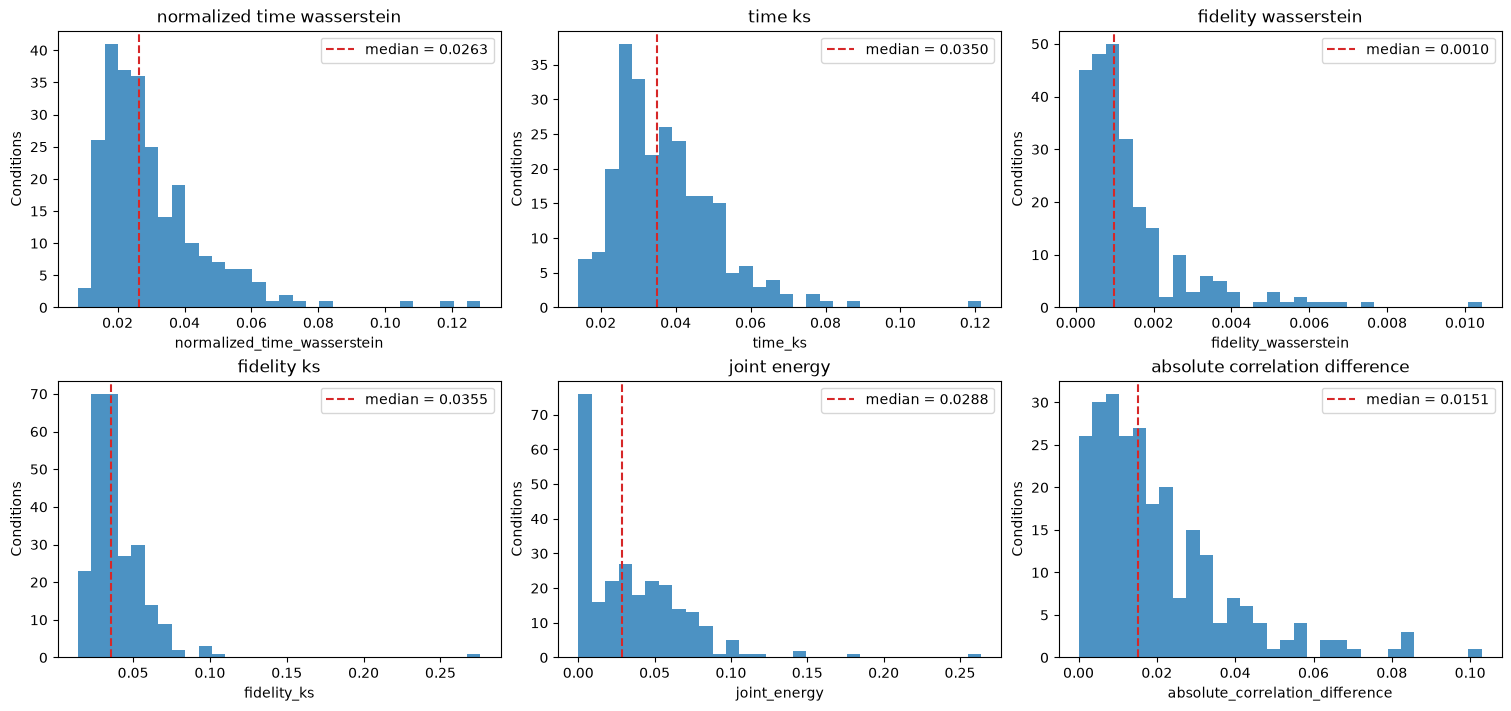

In [65]:
def plot_metric_distributions():
    """Plot the per-condition distribution of every sweep metric."""
    figure, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
    for axis, metric in zip(axes.ravel(), SWEEP_METRICS):
        axis.hist(results[metric], bins=30, alpha=0.8)
        median = float(results[metric].median())
        axis.axvline(median, color="tab:red", linestyle="--", label=f"median = {median:.4f}")
        axis.set(title=metric.replace("_", " "), xlabel=metric, ylabel="Conditions")
        axis.legend()
    plt.show()


plot_metric_distributions()

## Breakdown by chain length

Chain length is the structural variable the Transformer must generalize over, so per-node-count
medians show whether accuracy degrades as chains grow.

In [66]:
by_nodes = results.groupby("nodes")[SWEEP_METRICS].median()
by_nodes.insert(0, "conditions", results.groupby("nodes").size())
by_nodes

,conditions,normalized_time_wasserstein,time_ks,fidelity_wasserstein,fidelity_ks,joint_energy,absolute_correlation_difference
nodes,,,,,,,
3,14,0.041043,0.05025,0.000265,0.04350,0.039151,0.017892
4,21,0.042646,0.04100,0.000483,0.03600,0.025294,0.020178
5,18,0.027324,0.03900,0.000539,0.03075,0.008570,0.016956
6,27,0.027109,0.03550,0.000654,0.03350,0.025525,0.016705
7,21,0.026447,0.03600,0.001102,0.03850,0.036520,0.020982
8,14,0.022629,0.03200,0.000671,0.03200,0.023900,0.015784
9,16,0.021563,0.03225,0.000869,0.03300,0.020968,0.014814
10,17,0.023871,0.02750,0.001319,0.03950,0.041959,0.014080
11,19,0.027943,0.03450,0.001144,0.03800,0.037588,0.010303


## Where does the surrogate struggle?

Error against chain length, total chain distance, and the SeQUeNCe mean service time. A trend in any
panel points at a region of configuration space that needs more training data.

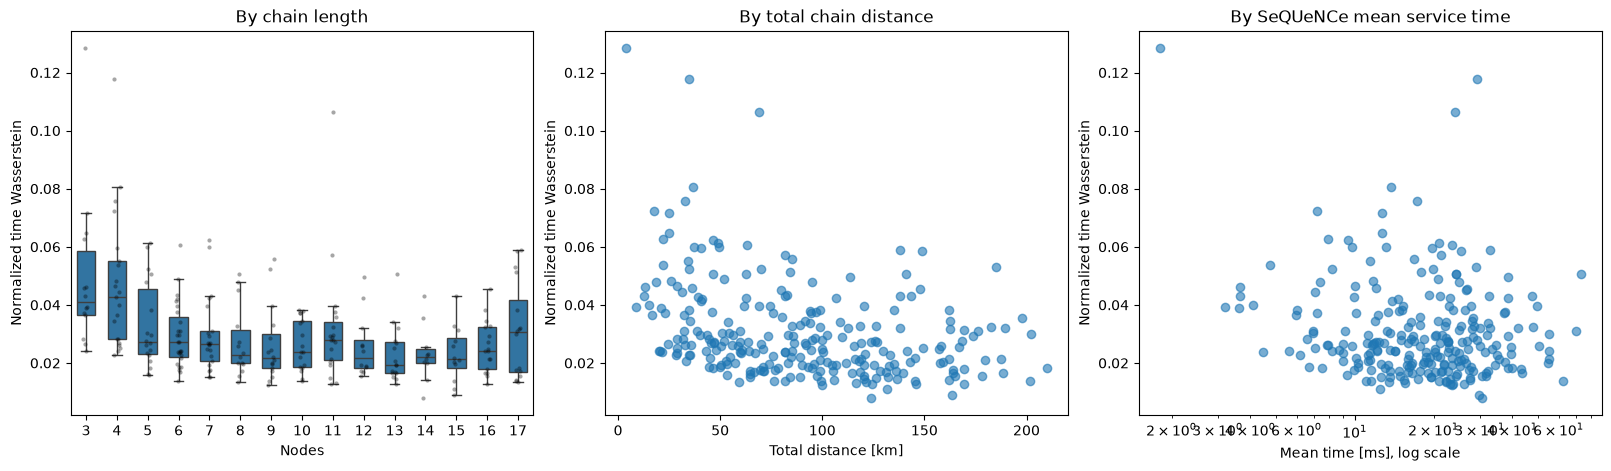

In [67]:
def plot_error_against_structure():
    """Plot normalized time Wasserstein against chain length, distance, and service time."""
    figure, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
    sns.boxplot(data=results, x="nodes", y="normalized_time_wasserstein", ax=axes[0], width=0.6, showfliers=False)
    sns.stripplot(data=results, x="nodes", y="normalized_time_wasserstein", ax=axes[0],
                  color="black", alpha=0.35, size=3)
    axes[0].set(title="By chain length", xlabel="Nodes", ylabel="Normalized time Wasserstein")

    axes[1].scatter(results["total_distance_km"], results["normalized_time_wasserstein"], alpha=0.6)
    axes[1].set(title="By total chain distance", xlabel="Total distance [km]", ylabel="Normalized time Wasserstein")

    axes[2].scatter(results["sequence_time_mean_ms"], results["normalized_time_wasserstein"], alpha=0.6)
    axes[2].set(xscale="log", title="By SeQUeNCe mean service time",
                xlabel="Mean time [ms], log scale", ylabel="Normalized time Wasserstein")
    plt.show()


plot_error_against_structure()

## Save per-condition metrics

In [68]:
SWEEP_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(SWEEP_CSV_PATH, index=False)
print(f"Saved {len(results)} condition rows to {SWEEP_CSV_PATH}")

Saved 250 condition rows to models/chain_condition_metrics.csv


Change `TEST_FILE_INDEX` and rerun to deep-dive another condition; the sweep already covers all of
them. Set `MODEL_PATH = PROJECT_ROOT / "models/model_name.pt"` when selecting a specific trained model.